# 01 · Your first real embedding map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute after installation. Download during this notebook: 0 bytes.
Source: Google / Google DeepMind AlphaEarth Foundations annual **2021**, CC-BY-4.0.
The bundled 5933-cell sample spans the San Francisco Bay Area and surroundings,
[-122.6,37.3,-121.6,38.3], approximately 88 × 111 km. It contains official
1280 m overview vectors (normalized sums of native AEF vectors), not 10 m
point samples or optical RGB. The complete checked bundle is about 2.1 MB.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")

CPU demo; outputs are saved in ./outputs


In [2]:
aef = load_demo("aef")
print(aef.features.shape)
print(aef.metadata["attribution"])
display(aef.samples.head())

(5933, 64)
The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind. © ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium.


,tile_id,center_lon,center_lat,minlon,minlat,maxlon,maxlat,utm_easting,utm_northing,aef_valid,...,lon1,lat1,lon2,lat2,lon3,lat3,class_name,dominant_fraction,reference_valid_fraction,demo_split
0,bay_x541600_y4128640,-122.530588,37.303457,-122.537845,37.297660,-122.523330,37.309254,541600,4128640,True,...,-122.523403,37.297660,-122.523330,37.309197,-122.537774,37.309254,water,1.0,1,train
1,bay_x542880_y4128640,-122.516145,37.303399,-122.523403,37.297601,-122.508886,37.309197,542880,4128640,True,...,-122.508961,37.297601,-122.508886,37.309138,-122.523330,37.309197,water,1.0,1,train
2,bay_x544160_y4128640,-122.501702,37.303339,-122.508961,37.297540,-122.494442,37.309138,544160,4128640,True,...,-122.494519,37.297540,-122.494442,37.309077,-122.508886,37.309138,water,1.0,1,train
3,bay_x545440_y4128640,-122.487259,37.303277,-122.494519,37.297477,-122.479998,37.309077,545440,4128640,True,...,-122.480077,37.297477,-122.479998,37.309015,-122.494442,37.309077,water,1.0,1,train
4,bay_x546720_y4128640,-122.472816,37.303214,-122.480077,37.297413,-122.465554,37.309015,546720,4128640,True,...,-122.465636,37.297413,-122.465554,37.308950,-122.479998,37.309015,water,1.0,1,train


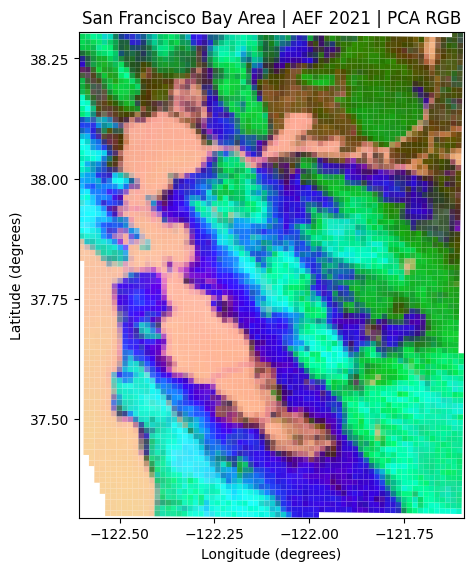

In [3]:
fig = plot_map(aef.samples, pca_colors(aef.features), title="San Francisco Bay Area | AEF 2021 | PCA RGB")
fig.savefig(out / "aef-pca.png", dpi=160)
plt.show()

Red/green/blue show the first three principal components, stretched at the
2nd/98th percentiles. PCA is fitted only for this descriptive map. Colors are
**not land-cover labels** and cannot be compared to separately fitted PCA maps.
North is up; map placement uses the stored bounds, never implicit array order.

To fetch these same points yourself, install `.[aef]`, then run
`from earth_embedding.demo import fetch_aef_demo; fresh = fetch_aef_demo()`.
This reads official COG ranges (network transfer depends on COG block layout,
potentially tens of MB), checks the expected sample SHA-256, and caches the array.
Subsequent `fetch_aef_demo(offline=True)` calls use only the checked cache.
Network errors raise a clear error; the bundled `load_demo("aef")` remains usable offline.